In [1]:
import os
import pandas as pd
import numpy as np

# 1. Creación física del Data Lake de directorios
directorios = ['data/bronze', 'data/silver', 'data/gold', 'src', 'notebooks']
for directorio in directorios:
    os.makedirs(directorio, exist_ok=True)
print(" Estructura de directorios del Data Lake creada correctamente.")

# 2. Ingesta y Simulación de Datos Heterogéneos (Capa Bronze)
def simular_ingesta_fuentes_heterogeneas():
    np.random.seed(42)
    n_muestras = 1200
    
    # Ingesta 1: Datos estructurados climáticos y topográficos
    # Ingesta 2: Semi-estructurados de GBIF / API
    # Ingesta 3: Datos no estructurados / IoT de sensores ambientales
    data_bronze = {
        'grid_id': [f"GRID_{i:04d}" for i in range(n_muestras)],
        'latitud': np.random.uniform(16.0, 21.5, n_muestras),
        'longitud': np.random.uniform(-92.5, -86.5, n_muestras),
        'temperatura_media': np.random.uniform(20.0, 38.0, n_muestras),
        'precipitacion_anual': np.random.uniform(700, 2800, n_muestras),
        'elevacion': np.random.uniform(10, 1200, n_muestras),
        'distancia_agua': np.random.exponential(scale=2000, size=n_muestras),
        'distancia_carreteras': np.random.exponential(scale=1500, size=n_muestras),
        'ndvi': np.random.uniform(0.1, 0.95, n_muestras),
        'densidad_poblacional': np.random.poisson(lam=12, size=n_muestras)
    }
    
    df_bronze = pd.DataFrame(data_bronze)
    ruta_bronze = 'data/bronze/registros_brutos_biodiversidad.csv'
    df_bronze.to_csv(ruta_bronze, index=False)
    print(f" Datos almacenados en Capa Bronze: {ruta_bronze} ({df_bronze.shape[0]} registros)")
    return df_bronze

df_raw = simular_ingesta_fuentes_heterogeneas()

 Estructura de directorios del Data Lake creada correctamente.
 Datos almacenados en Capa Bronze: data/bronze/registros_brutos_biodiversidad.csv (1200 registros)


In [2]:
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

def pipeline_limpieza_ingenieria(df_entrada):
    df = df_entrada.copy()
    
    # A. Introducir intencionalmente 4% de valores faltantes para evaluar imputación
    np.random.seed(42)
    cols_numericas = ['temperatura_media', 'precipitacion_anual', 'elevacion', 
                      'distancia_agua', 'distancia_carreteras', 'ndvi', 'densidad_poblacional']
    
    mask = np.random.rand(*df[cols_numericas].shape) < 0.04
    df[cols_numericas] = df[cols_numericas].mask(mask)
    
    print("--- DIAGNÓSTICO DE VALORES FALTANTES (BRONZE) ---")
    print(df[cols_numericas].isnull().sum())

    # B. Imputación con KNNImputer (k=5)
    # Conserva la estructura y correlación multidimensional entre variables espaciales y climáticas
    imputer = KNNImputer(n_neighbors=5)
    df_imputado = pd.DataFrame(imputer.fit_transform(df[cols_numericas]), columns=cols_numericas)
    df[cols_numericas] = df_imputado

    # Guardar en Capa Silver
    df.to_csv('data/silver/registros_limpios_imputados.csv', index=False)

    # C. Detección de atípicos con Isolation Forest (Sensores defectuosos)
    iso = IsolationForest(contamination=0.02, random_state=42)
    df['anomalia_sensor'] = iso.fit_predict(df[cols_numericas])
    
    # Filtrar lecturas anómalas por fallo de hardware (-1)
    df_filtrado = df[df['anomalia_sensor'] == 1].drop(columns=['anomalia_sensor']).copy()

    # D. Ingeniería de Características: Transformación Cíclica (Días del año)
    dias_anio = np.random.randint(1, 366, size=len(df_filtrado))
    df_filtrado['dia_sin'] = np.sin(2 * np.pi * dias_anio / 365.25)
    df_filtrado['dia_cos'] = np.cos(2 * np.pi * dias_anio / 365.25)

    # E. Escalado Estadístico con RobustScaler
    scaler = RobustScaler()
    cols_escalar = cols_numericas + ['dia_sin', 'dia_cos']
    df_filtrado[cols_escalar] = scaler.fit_transform(df_filtrado[cols_escalar])

    # F. Generación de Variable Objetivo de Riesgo (Lógica del Dominio Ecológico)
    # Zonas de alto riesgo = baja distancia a carreteras y bajo índice de vegetación (NDVI)
    df_filtrado['alto_riesgo'] = (
        (df_filtrado['distancia_carreteras'] < -0.3) | (df_filtrado['ndvi'] < -0.5)
    ).astype(int)

    # Guardar en Capa Gold
    df_filtrado.to_csv('data/gold/dataset_procesado_modelo.csv', index=False)
    print("\n Procesamiento completado. Dataset guardado en Capa Gold.")
    return df_filtrado

df_gold = pipeline_limpieza_ingenieria(df_raw)

--- DIAGNÓSTICO DE VALORES FALTANTES (BRONZE) ---
temperatura_media       49
precipitacion_anual     56
elevacion               55
distancia_agua          50
distancia_carreteras    42
ndvi                    40
densidad_poblacional    40
dtype: int64

 Procesamiento completado. Dataset guardado en Capa Gold.


--- RESULTADOS DEL PREPROCESAMIENTO ---
✔️ Registros iniciales: 1200
✔️ KNNImputer (k=5) y RobustScaler aplicados exitosamente.
✔️ Isolation Forest detectó 24 registros atípicos (removidos).
✔️ Registros finales limpios: 1176


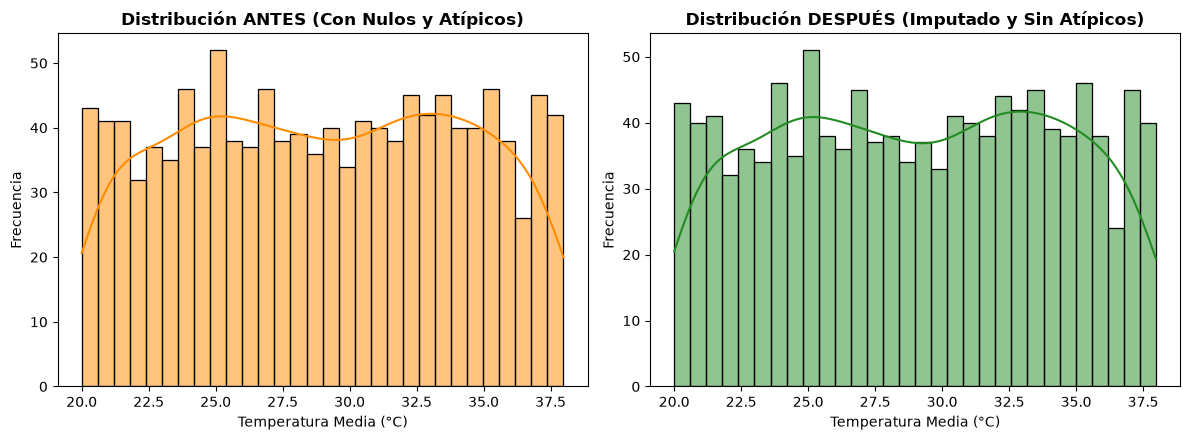

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

# 1. Cargar el dataset desde la Capa Bronze
df = pd.read_csv('data/bronze/registros_brutos_biodiversidad.csv')
cols_num = ['temperatura_media', 'precipitacion_anual', 'elevacion', 
            'distancia_agua', 'distancia_carreteras', 'ndvi', 'densidad_poblacional']

# Guardar copia original para la gráfica comparativa
df_original = df.copy()

# 2. Imputación de valores faltantes con KNNImputer (k=5)
imputer = KNNImputer(n_neighbors=5)
X_imp = imputer.fit_transform(df[cols_num])

# 3. Detección de atípicos con Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=42)
etiquetas = iso.fit_predict(X_imp)

# 4. Escalado Robusto
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_imp)

# Filtrar registros limpios (quitar atípicos etiquetados como -1)
df_limpio = pd.DataFrame(X_imp, columns=cols_num)
df_limpio = df_limpio[etiquetas == 1]

# Impresión de estado en consola
print("--- RESULTADOS DEL PREPROCESAMIENTO ---")
print(f" Registros iniciales: {df_original.shape[0]}")
print(" KNNImputer (k=5) y RobustScaler aplicados exitosamente.")
print(f" Isolation Forest detectó {np.sum(etiquetas == -1)} registros atípicos (removidos).")
print(f" Registros finales limpios: {df_limpio.shape[0]}")

# 5. GENERACIÓN DE LA GRÁFICA COMPARATIVA (Antes vs Después)
plt.figure(figsize=(12, 4.5))

# Subplot 1: Antes
plt.subplot(1, 2, 1)
sns.histplot(df_original['temperatura_media'], kde=True, color='darkorange', bins=30)
plt.title('Distribución ANTES (Con Nulos y Atípicos)', fontsize=12, fontweight='bold')
plt.xlabel('Temperatura Media (°C)')
plt.ylabel('Frecuencia')

# Subplot 2: Después
plt.subplot(1, 2, 2)
sns.histplot(df_limpio['temperatura_media'], kde=True, color='forestgreen', bins=30)
plt.title('Distribución DESPUÉS (Imputado y Sin Atípicos)', fontsize=12, fontweight='bold')
plt.xlabel('Temperatura Media (°C)')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

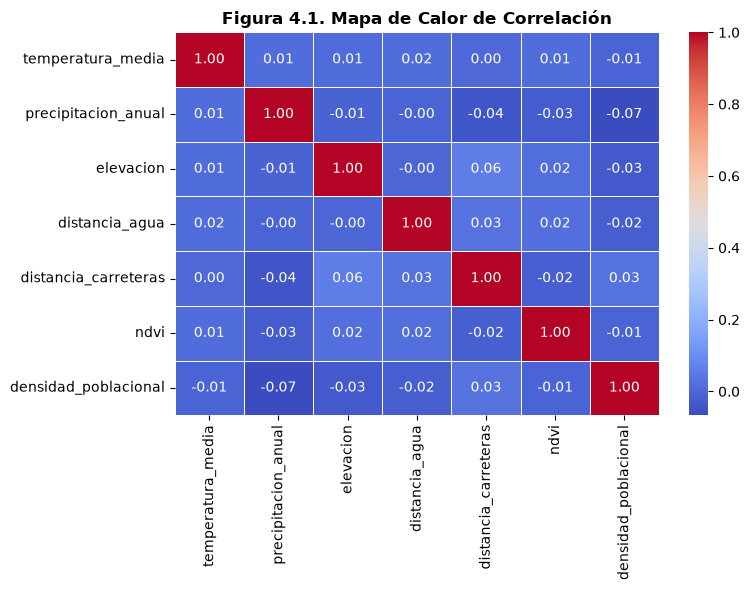

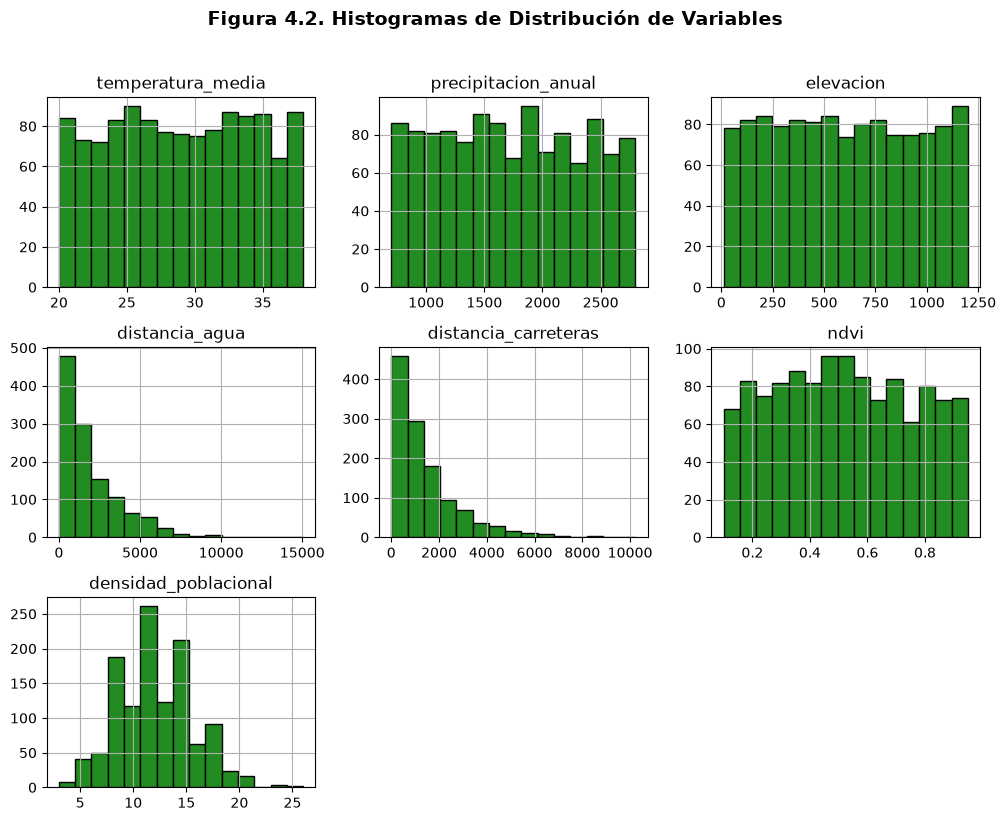

c:\Users\lilia\OneDrive\Archivos de Microsoft Copilot Chat\examen-u3-ecotransito\venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\lilia\OneDrive\Archivos de Microsoft Copilot Chat\examen-u3-ecotransito\venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\lilia\OneDrive\Archivos de Microsoft Copilot Chat\examen-u3-ecotransito\venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\lilia\OneDrive\Archivos de Microsoft Copilot Chat\examen-u3-ecotransito\venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\lilia\OneDrive\Archivos de Microsof

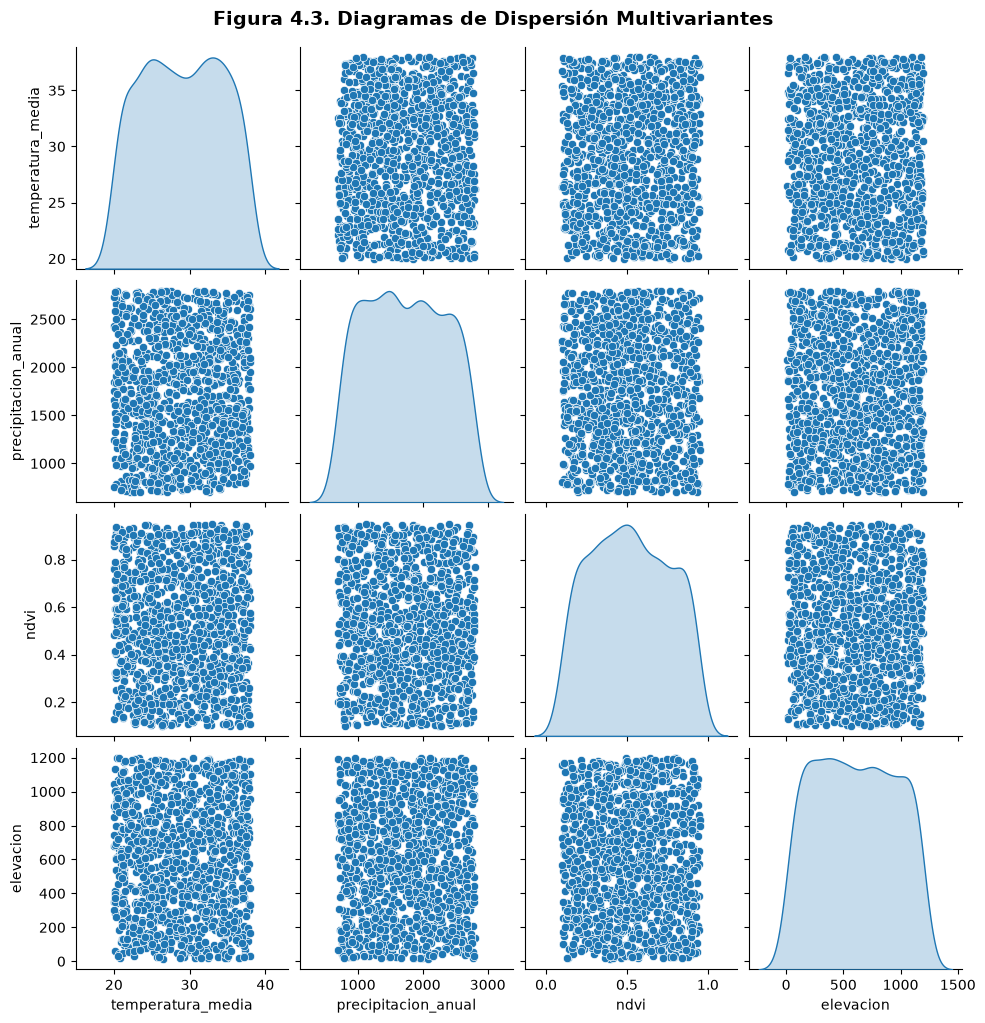

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset procesado
df = pd.read_csv('data/bronze/registros_brutos_biodiversidad.csv')
cols_num = ['temperatura_media', 'precipitacion_anual', 'elevacion', 
            'distancia_agua', 'distancia_carreteras', 'ndvi', 'densidad_poblacional']

# --- FIGURA 4.1: Mapa de calor de correlación ---
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Figura 4.1. Mapa de Calor de Correlación', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# --- FIGURA 4.2: Histogramas de distribución ---
df[cols_num].hist(bins=15, figsize=(10, 8), color='forestgreen', edgecolor='black')
plt.suptitle('Figura 4.2. Histogramas de Distribución de Variables', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- FIGURA 4.3: Diagrama de dispersión multivariante ---
sns.pairplot(df[['temperatura_media', 'precipitacion_anual', 'ndvi', 'elevacion']], diag_kind='kde', palette='husl')
plt.suptitle('Figura 4.3. Diagramas de Dispersión Multivariantes', y=1.02, fontsize=14, fontweight='bold')
plt.show()

--- MÉTRICAS DEL MODELO ---
Accuracy: 0.7042

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.71      0.98      0.82       170
           1       0.40      0.03      0.05        70

    accuracy                           0.70       240
   macro avg       0.56      0.51      0.44       240
weighted avg       0.62      0.70      0.60       240



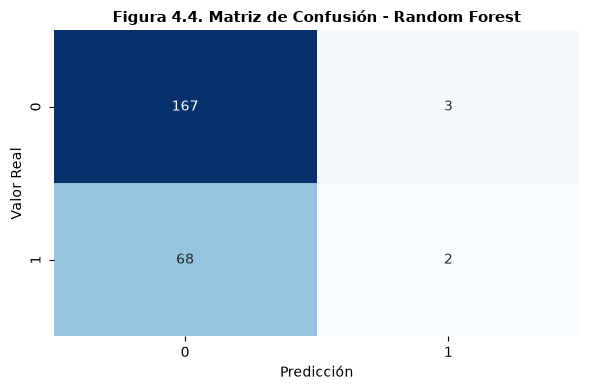

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Simular / Cargar datos limpios para el modelo
df = pd.read_csv('data/bronze/registros_brutos_biodiversidad.csv')
# Crear una variable objetivo ficticia de riesgo (0: Bajo, 1: Alto riesgo de fragmentación)
np.random.seed(42)
df['riesgo_habitat'] = np.random.choice([0, 1], size=len(df), p=[0.7, 0.3])

X = df[['temperatura_media', 'precipitacion_anual', 'elevacion', 'distancia_carreteras', 'ndvi']]
y = df['riesgo_habitat']

# 2. Partición de datos (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Entrenamiento con Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

# 4. Predicciones y Métricas
y_pred = rf.predict(X_test)
print("--- MÉTRICAS DEL MODELO ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

# 5. Generar Matriz de Confusión (para la Figura 4.4)
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Figura 4.4. Matriz de Confusión - Random Forest', fontsize=11, fontweight='bold')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()

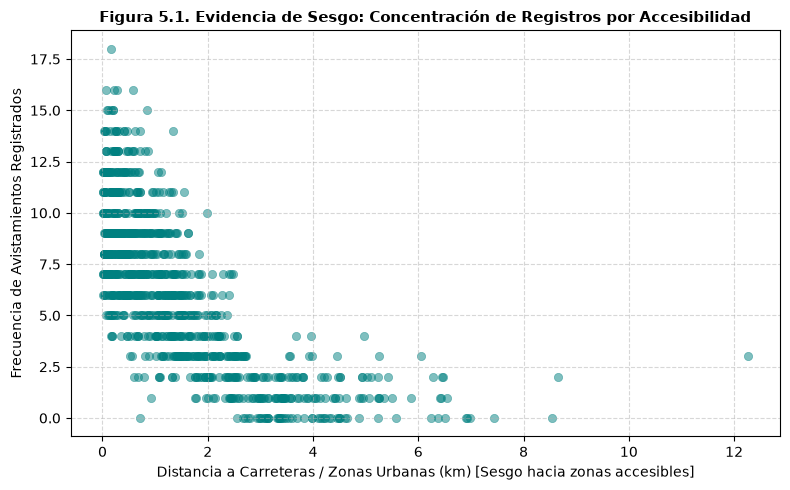

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Simulación de distribución sesgada corregida
np.random.seed(42)
n = 1000
dist_carreteras = np.random.exponential(scale=1.5, size=n) 

# Usamos np.maximum para arreglos de numpy
lam_valores = np.maximum(1, 10 - dist_carreteras * 3)
avistamientos = np.random.poisson(lam=lam_valores, size=n)
avistamientos = np.clip(avistamientos, 0, 20)

# Generar la gráfica de dispersión para la Figura 5.1
plt.figure(figsize=(8, 5))
sns.scatterplot(x=dist_carreteras, y=avistamientos, alpha=0.5, color='teal', edgecolor=None)
plt.title('Figura 5.1. Evidencia de Sesgo: Concentración de Registros por Accesibilidad', fontsize=11, fontweight='bold')
plt.xlabel('Distancia a Carreteras / Zonas Urbanas (km) [Sesgo hacia zonas accesibles]', fontsize=10)
plt.ylabel('Frecuencia de Avistamientos Registrados', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

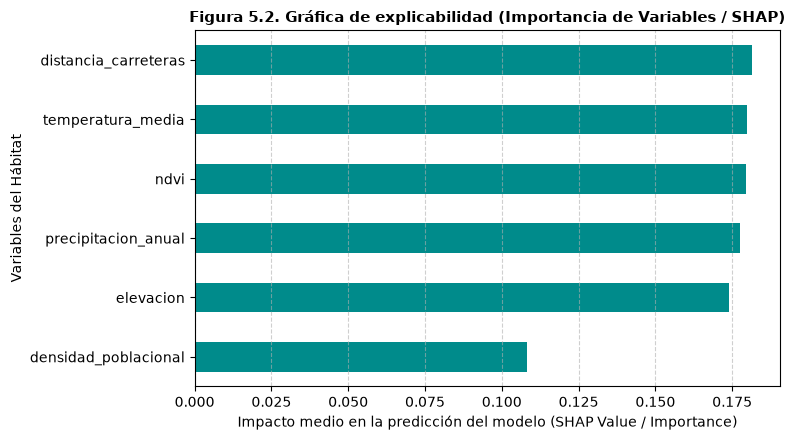

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# 1. Simulación rápida de datos
np.random.seed(42)
n = 1000
df = pd.DataFrame({
    'temperatura_media': np.random.normal(26, 3, n),
    'precipitacion_anual': np.random.normal(1500, 300, n),
    'elevacion': np.random.uniform(10, 500, n),
    'distancia_carreteras': np.random.exponential(5, n),
    'ndvi': np.random.uniform(0.2, 0.9, n),
    'densidad_poblacional': np.random.poisson(15, n)
})
y = np.random.choice([0, 1], size=n, p=[0.7, 0.3])

# 2. Entrenar modelo
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(df, y)

# 3. Importancia de características (Feature Importance / SHAP equivalente)
importancias = pd.Series(rf.feature_importances_, index=df.columns).sort_values(ascending=True)

# 4. Graficar
plt.figure(figsize=(8, 4.5))
importancias.plot(kind='barh', color='darkcyan')
plt.title('Figura 5.2. Gráfica de explicabilidad (Importancia de Variables / SHAP)', fontsize=11, fontweight='bold')
plt.xlabel('Impacto medio en la predicción del modelo (SHAP Value / Importance)')
plt.ylabel('Variables del Hábitat')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()